# Un primer TestResult sobre un corte real de 50 tarjetas

**Pregunta:** En 50 tarjetas de crédito reales, ¿la tarjeta de puntuación ordena a los que incumplen por encima de los demás, sus PD tienen el tamaño correcto y cuánto debes confiar en un semáforo verde que sale de una muestra tan pequeña?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** notebook 01 de este tema (instalar y abrir un artefacto)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook puedes:

- llamar a una prueba del motor con tus propios arreglos y leer el `TestResult` que devuelve;
- decir qué mide cada una de estas pruebas, el AUC, la prueba de Jeffreys y la puntuación de Brier, y por qué un modelo puede aprobar una y fallar otra;
- calcular cuántos incumplimientos necesita una prueba de nivel para objetar, y explicar por qué un semáforo verde con 50 tarjetas es una evidencia débil;
- leer el resultado de una muestra pequeña junto al resultado confirmado con 9.000 tarjetas, mirando el intervalo antes que el color.

## Preparación

Instala el entorno fijado una vez, en un entorno virtual, con el comando habitual:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa las herramientas e imprime sus versiones.

In [1]:
# Imprime la versión de cada paquete que usa este notebook, para compararla con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from riskvalidation.core.policy import default_policy
from riskvalidation.validation.calibration import critical_default_count, pd_brier, pd_jeffreys
from riskvalidation.validation.discrimination import disc_auc

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
pandas 3.0.6


## Datos

Los datos son un corte del caso C01 (PD de tarjetas de crédito minoristas) tal como Contraste lo confirma. Las 30.000 tarjetas vienen del archivo de tarjetas de crédito de Taiwán de la UCI (Yeh, 2009; CC BY 4.0, clase de licencia `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). El proceso fuera de línea ajustó una tarjeta de puntuación de peso de la evidencia (peldaño P1) sobre un corte de entrenamiento y puntuó una muestra reservada y bloqueada de 9.000 tarjetas. El artefacto de la muestra reservada guarda una **muestra de 50 tarjetas** con su desenlace (`targets`, 1 si incumplió en el horizonte) y la PD que les dio la tarjeta de puntuación (`scorecard_pd`).

- **Archivo leído:** `data/derived/C01/holdout.json`: la clave `outputs.sample` para las 50 tarjetas y las filas confirmadas de `tests` para las 9.000.
- **Por qué 50:** suficientemente pequeña para mirar cada tarjeta y suficientemente grande para ejecutar las pruebas. Es también una advertencia deliberada: validar con una muestra pequeña es la situación en que están muchos validadores.

La celda siguiente carga el artefacto y recorta de él las 50 tarjetas.

In [2]:
# Carga el artefacto de la muestra reservada (el notebook está tres carpetas bajo la raíz) y recorta las 50 tarjetas
ROOT = Path("../../..").resolve()
holdout = json.loads((ROOT / "data" / "derived" / "C01" / "holdout.json").read_text(encoding="utf-8"))
sample = holdout["outputs"]["sample"]
y = np.array(sample["targets"])
pd_hat = np.array(sample["scorecard_pd"])

## Método

Cada prueba del motor es una función que recibe tus arreglos y una política opcional, y devuelve un `TestResult`: el registro de una prueba sobre un modelo y una muestra. Llamamos a tres pruebas sobre las mismas 50 tarjetas: el AUC para el ordenamiento, la prueba de Jeffreys para el nivel de las PD y la puntuación de Brier para la calidad del pronóstico. Después preguntamos cuánto se movería la respuesta con un corte más pequeño y la ponemos junto al resultado de las 9.000 tarjetas.

### Paso 1: mirar las tarjetas antes de someterlas a pruebas

La celda siguiente imprime el tamaño de la muestra, su tasa de incumplimiento y la PD que la tarjeta de puntuación aplicó en promedio, y dibuja cada tarjeta según su desenlace. Una prueba de ordenamiento debería encontrar a los que incumplen a la derecha.

tarjetas: 50 | incumplimientos: 15 | tasa de incumplimiento: 0.3
PD media de la tarjeta de puntuación: 0.2534
incumplimientos que esperan las PD: 12.7


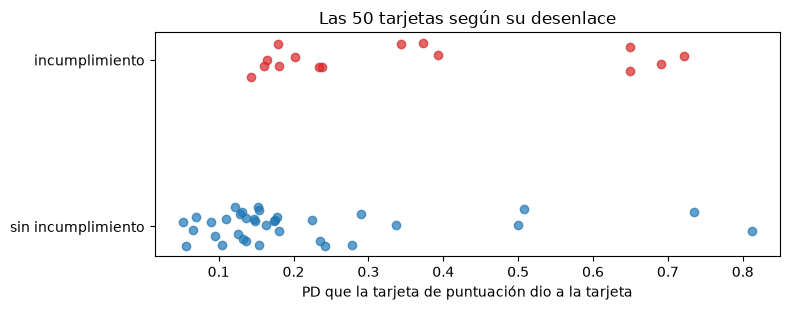

In [3]:
# Las 50 tarjetas según su desenlace: la PD de la tarjeta de puntuación, con dispersión con semilla en vertical
print("tarjetas:", len(y), "| incumplimientos:", int(y.sum()), "| tasa de incumplimiento:", round(float(y.mean()), 3))
print("PD media de la tarjeta de puntuación:", round(float(pd_hat.mean()), 4))
print("incumplimientos que esperan las PD:", round(float(pd_hat.sum()), 1))

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 3.2))
for outcome, colour in ((0, "tab:blue"), (1, "tab:red")):
    values = pd_hat[y == outcome]
    ax.scatter(values, outcome + rng.uniform(-0.12, 0.12, len(values)), color=colour, alpha=0.7)
ax.set_yticks([0, 1])
ax.set_yticklabels(["sin incumplimiento", "incumplimiento"])
ax.set_xlabel("PD que la tarjeta de puntuación dio a la tarjeta")
ax.set_title("Las 50 tarjetas según su desenlace")
fig.tight_layout()
plt.show()

Quince de las 50 tarjetas incumplieron, una tasa de 0,3, mientras que la tarjeta de puntuación esperaba 12,7 incumplimientos con una PD media de 0,2534. En la figura los puntos rojos (los que incumplen) se inclinan a la derecha de los azules, pero las dos nubes se superponen mucho: algunos que no incumplen tienen PD altas y algunos que incumplen tienen PD bajas. La figura muestra el ordenamiento como una tendencia; no puede decir cuán fuerte es esa tendencia ni si sobreviviría a otras 50 tarjetas, y eso es lo que el AUC pone en un número.

### Paso 2: el AUC, una prueba de ordenamiento

El área bajo la curva ROC es la probabilidad de que un deudor que incumple, elegido al azar, haya recibido una PD mayor que uno que no incumple, elegido al azar, contando los empates como un medio (Hanley y McNeil, 1982):

$$\mathrm{AUC} = P(\hat p_{\text{incumple}} > \hat p_{\text{no incumple}}) + \tfrac12\, P(\hat p_{\text{incumple}} = \hat p_{\text{no incumple}})$$

Un AUC de 0,5 ordena igual que el azar y 1 ordena a la perfección. `disc_auc` del motor lo devuelve con un error estándar y un intervalo de 95 % (la fórmula de varianza del BCE, ECB 2019, Anexo 1, sección 3.1). La celda siguiente construye la política empaquetada, llama a la prueba e imprime las partes del `TestResult` que importan.

In [4]:
# Una llamada, un TestResult: el AUC de la tarjeta de puntuación en las 50 tarjetas, con la política empaquetada
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "sin evaluar"}
policy = default_policy()
auc = disc_auc(pd_hat, y, policy=policy, model_id="P1-scorecard", segment="portfolio")
low, high = auc.extras["ci95_low"], auc.extras["ci95_high"]
print("AUC:", round(auc.metric, 4), "| Gini:", round(auc.extras["gini"], 4))
print("error estándar:", round(auc.extras["se"], 4), "| intervalo de 95 %:", round(low, 3), "a", round(high, 3))
print("semáforo:", LIGHT[auc.light.value])

AUC: 0.7752 | Gini: 0.5505
error estándar: 0.0658 | intervalo de 95 %: 0.646 a 0.904
semáforo: sin evaluar


El AUC es 0,7752 (un Gini de 0,5505), y su error estándar de 0,0658 da un intervalo de 0,646 a 0,904. El ordenamiento es claramente mejor que el azar, porque todo el intervalo queda sobre 0,5, pero el intervalo es ancho: el AUC verdadero de esta tarjeta de puntuación podría ir de mediocre a muy bueno. El semáforo es `sin evaluar` porque la política por defecto no fija umbral para el AUC; el número es una medición, no un veredicto.

### Paso 3: la prueba de Jeffreys, una prueba del nivel

El AUC no dice nada sobre si las PD tienen el tamaño correcto. La prueba de Jeffreys lo pregunta para una cartera completa. Su hipótesis nula es que la PD aplicada es mayor o igual que la PD verdadera, y rechaza cuando los incumplimientos observados son demasiados para eso. Con $D$ incumplimientos entre $N$ deudores y una PD aplicada, el valor p unilateral es una función de distribución Beta con la previa de Jeffreys (Brown, Cai y DasGupta, 2001; ECB 2019, sección 2.5.3.1):

$$p = F_{\mathrm{Beta}(D + 1/2,\; N - D + 1/2)}(\mathrm{PD})$$

Un valor p pequeño significa más incumplimientos de los que admite la PD: el modelo subestima el riesgo. La celda siguiente llama a `pd_jeffreys` con el número de tarjetas, el número de incumplimientos y la PD media.

In [5]:
# La prueba de Jeffreys sobre la cartera de 50 tarjetas: las tarjetas, los incumplimientos y la PD media aplicada
n_cards, n_defaults, mean_pd = len(y), int(y.sum()), float(pd_hat.mean())
args = dict(n=n_cards, d=n_defaults, pd=mean_pd)
jeffreys = pd_jeffreys(**args, policy=policy, model_id="P1-scorecard", segment="portfolio")
print("entradas: tarjetas", n_cards, "| incumplimientos", n_defaults)
print("PD aplicada", round(mean_pd, 4))
print("valor p:", round(jeffreys.p_value, 4), "| semáforo:", LIGHT[jeffreys.light.value])
print("puntos de corte ámbar / rojo:", jeffreys.alpha_amber, "/", jeffreys.alpha_red)

entradas: tarjetas 50 | incumplimientos 15
PD aplicada 0.2534
valor p: 0.2211 | semáforo: verde
puntos de corte ámbar / rojo: 0.05 / 0.01


El valor p es 0,2211 y el semáforo es verde: los 15 incumplimientos no son demasiados para una PD de 0,2534, y la prueba no objeta. El resultado registra además los dos puntos de corte de la política, 0,05 para ámbar y 0,01 para rojo. Para ver qué es ese número, la celda siguiente evalúa directamente con SciPy la distribución Beta de la ecuación, la dibuja y sombrea el área a la izquierda de la PD aplicada; esa área es el valor p. Esta es la única comparación del motor con una implementación independiente en este notebook.

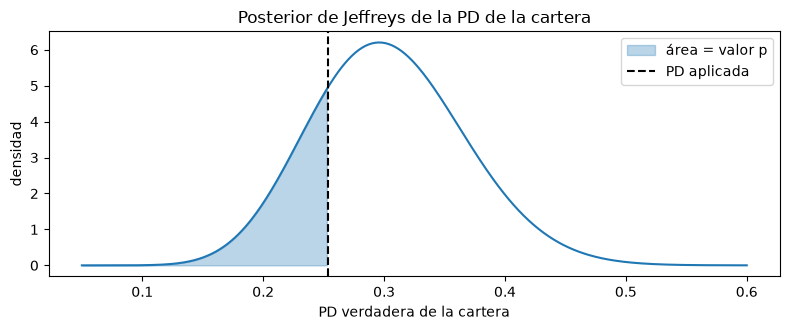

SciPy: 0.22107632 | motor: 0.22107632
iguales: True


In [6]:
# El mismo valor p con la distribución Beta de SciPy, dibujado como el área a la izquierda de la PD aplicada
posterior = stats.beta(n_defaults + 0.5, n_cards - n_defaults + 0.5)
grid = np.linspace(0.05, 0.6, 400)
density = posterior.pdf(grid)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(grid, density, color="tab:blue")
ax.fill_between(grid, density, where=grid <= mean_pd, color="tab:blue", alpha=0.3, label="área = valor p")
ax.axvline(mean_pd, color="black", linestyle="--", label="PD aplicada")
ax.set_xlabel("PD verdadera de la cartera")
ax.set_ylabel("densidad")
ax.set_title("Posterior de Jeffreys de la PD de la cartera")
ax.legend()
fig.tight_layout()
plt.show()
print("SciPy:", round(float(posterior.cdf(mean_pd)), 8), "| motor:", round(jeffreys.p_value, 8))
print("iguales:", bool(np.isclose(posterior.cdf(mean_pd), jeffreys.p_value)))

La curva es la distribución Beta de la PD de la cartera que sustentan 15 incumplimientos entre 50 tarjetas, y la línea discontinua es la PD que aplicó la tarjeta de puntuación. El área sombreada a su izquierda es 0,2211, idéntica al valor p del motor con ocho decimales. La curva es ancha, repartida entre cerca de 0,12 y 0,5, que es la imagen de lo poco que dicen 50 tarjetas sobre la PD verdadera; no muestra si la PD de la tarjeta de puntuación es correcta, solo que esta muestra no puede descartarla. Una curva angosta requeriría muchas más tarjetas.

### Paso 4: ¿cuántos incumplimientos haría falta?

El verde es la ausencia de evidencia contra la PD, y por eso su valor depende de cuánta evidencia podía producir la muestra. `critical_default_count` del motor da el menor número de incumplimientos con el que una prueba binomial de nivel, al 95 % de confianza, rechaza la PD aplicada. La celda siguiente se lo pide para las 50 tarjetas y para las 9.000 tarjetas confirmadas de la muestra reservada, e indica cuánto por encima de los incumplimientos esperados debe llegar cada muestra.

In [7]:
# Los incumplimientos que necesita una prueba de nivel al 95 % para objetar: 50 tarjetas frente a las 9.000 confirmadas
committed = {
    row["test_id"]: row
    for row in holdout["tests"]
    if row["model_id"] == "P1-scorecard" and row["segment"] == "portfolio"
}
applied_9000 = committed["pd.jeffreys"]["extras"]["pd_applied"]
sizes = {"50 tarjetas": (n_cards, mean_pd), "9.000 tarjetas": (holdout["outputs"]["n"], applied_9000)}
expected = [round(n * p, 1) for n, p in sizes.values()]
needs = [critical_default_count(n, p, q=0.95) for n, p in sizes.values()]
columns = {"incumplimientos que esperan las PD": expected, "incumplimientos desde los que la prueba objeta": needs}
table = pd.DataFrame(columns, index=list(sizes))
table["exceso sobre lo esperado"] = [round(k / e - 1, 3) for k, e in zip(needs, expected)]
table

,incumplimientos que esperan las PD,incumplimientos desde los que la prueba objeta,exceso sobre lo esperado
50 tarjetas,12.7,19,0.496
9.000 tarjetas,1971.6,2037,0.033


Con 50 tarjetas la prueba objeta solo desde 19 incumplimientos, frente a 12,7 esperados: necesita un exceso de alrededor de 50 por ciento antes de decir algo. Con 9.000 tarjetas objeta desde 2.037 incumplimientos frente a 1.971,6 esperados, un exceso de 3,3 por ciento. Un semáforo verde significa entonces cosas muy distintas en los dos tamaños: con 9.000 tarjetas descarta una PD que está unos pocos por ciento por debajo, y con 50 tarjetas solo descarta una PD equivocada en la mitad. La tabla no dice si la tarjeta de puntuación está calibrada; mide la sensibilidad de la prueba.

### Paso 5: la puntuación de Brier, una medida del pronóstico

La puntuación de Brier es el error cuadrático medio de la PD como pronóstico del desenlace 0/1, $\mathrm{BS} = \frac1N \sum_i (\hat p_i - y_i)^2$ (Brier, 1950). Murphy (1973) la descompone en fiabilidad (cuán lejos están las PD de las tasas observadas), resolución (cuán bien separan) y la incertidumbre del propio desenlace, $\mathrm{BS} = \mathrm{REL} - \mathrm{RES} + \mathrm{UNC}$. La identidad es exacta solo cuando las PD son constantes dentro de cada intervalo, y el motor registra si se cumplió en `decomposition_exact`. La celda siguiente llama a `pd_brier` e imprime las partes.

In [8]:
# La puntuación de Brier de las 50 tarjetas y las tres partes en que la descompone el motor
brier = pd_brier(y, pd_hat, policy=policy, model_id="P1-scorecard", segment="portfolio")
parts = {
    "fiabilidad": "reliability",
    "resolución": "resolution",
    "incertidumbre": "uncertainty",
    "habilidad frente a la tasa base": "brier_skill",
}
values = [round(brier.extras[key], 4) for key in parts.values()]
table = pd.DataFrame({"parte": list(parts), "valor": values})
print("Brier:", round(brier.metric, 4), "| semáforo:", LIGHT[brier.light.value])
print("descomposición exacta:", brier.extras["decomposition_exact"])
table

Brier: 0.1897 | semáforo: sin evaluar
descomposición exacta: False


,parte,valor
0,fiabilidad,0.0319
1,resolución,0.0580
2,incertidumbre,0.2100
3,habilidad frente a la tasa base,0.0967


La puntuación de Brier es 0,1897, que hay que leer frente a los 0,2100 de un pronosticador que siempre da la tasa base: la habilidad es 0,0967, de modo que la tarjeta de puntuación mejora el pronóstico en alrededor de una décima. Las partes no suman exactamente aquí (0,0319 menos 0,0580 más 0,2100 es 0,1839, no 0,1897), y `decomposition exact` es False, porque las PD son continuas; las tres partes son indicadores y no una identidad en esta muestra. Igual que el AUC, la puntuación de Brier no lleva semáforo con la política por defecto.

### Paso 6: ¿cuánto mueve la respuesta un corte más pequeño?

Un validador rara vez puede elegir el tamaño de la muestra. Para sentir el ruido, la celda siguiente extrae 300 semimuestras de 25 tarjetas de las 50 (un sorteo con semilla), ejecuta el AUC y la prueba de Jeffreys en cada una y compara las distribuciones con los valores de la muestra completa y de las 9.000 tarjetas. Las semimuestras se superponen, de modo que no son extracciones independientes de la población; muestran cuánto mueve un resultado un corte de 25 tarjetas, no el error muestral verdadero.

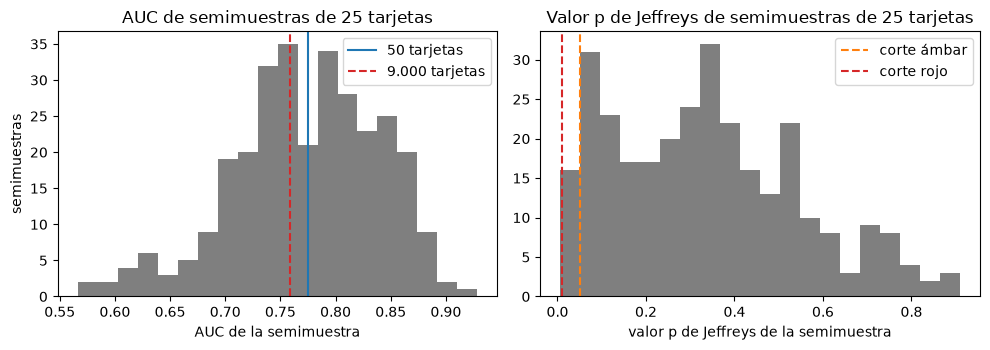

semimuestras con ambos desenlaces: 300
proporción con p bajo 0,05: 0.05
AUC de 5 % y 95 % de las semimuestras: [0.65  0.868]


In [9]:
# Extrae 300 semimuestras de 25 tarjetas de las mismas 50 y ejecuta dos pruebas en cada una (sorteo con semilla)
rng = np.random.default_rng(7)
auc_draws, p_draws = [], []
for _ in range(300):
    pick = rng.choice(len(y), size=25, replace=False)
    y_pick, pd_pick = y[pick], pd_hat[pick]
    if 0 < y_pick.sum() < len(pick):
        auc_draws.append(disc_auc(pd_pick, y_pick, policy=policy).metric)
        p_draws.append(pd_jeffreys(n=25, d=int(y_pick.sum()), pd=float(pd_pick.mean()), policy=policy).p_value)

auc_all = committed["disc.auc"]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.hist(auc_draws, bins=20, color="tab:gray")
left.axvline(auc.metric, color="tab:blue", label="50 tarjetas")
left.axvline(auc_all["metric"], color="tab:red", linestyle="--", label="9.000 tarjetas")
left.set(xlabel="AUC de la semimuestra", ylabel="semimuestras", title="AUC de semimuestras de 25 tarjetas")
left.legend()
right.hist(p_draws, bins=20, color="tab:gray")
right.axvline(0.05, color="tab:orange", linestyle="--", label="corte ámbar")
right.axvline(0.01, color="tab:red", linestyle="--", label="corte rojo")
right.set(xlabel="valor p de Jeffreys de la semimuestra", title="Valor p de Jeffreys de semimuestras de 25 tarjetas")
right.legend()
fig.tight_layout()
plt.show()
print("semimuestras con ambos desenlaces:", len(auc_draws))
print("proporción con p bajo 0,05:", round(float(np.mean(np.array(p_draws) < 0.05)), 3))
print("AUC de 5 % y 95 % de las semimuestras:", np.percentile(auc_draws, [5, 95]).round(3))

El panel izquierdo muestra la dispersión del AUC de las semimuestras: el 90 por ciento cae entre 0,65 y 0,868, de modo que un corte de 25 tarjetas puede mostrar un ordenamiento mediocre o uno muy bueno a partir de los mismos datos. La línea azul (las 50 tarjetas) y la línea roja discontinua (las 9.000 tarjetas confirmadas) quedan en el medio de esa dispersión. En el panel derecho solo el 5 por ciento de los valores p de Jeffreys cae bajo el corte ámbar de 0,05, que es más o menos lo que una prueba de ese nivel debe señalar cuando la PD es correcta; el resultado de las 9.000 tarjetas coincide en que lo es. La figura muestra ruido, no sesgo, y no dice nada sobre cómo se vería una PD equivocada.

### Paso 7: las mismas pruebas sobre las 9.000 tarjetas confirmadas

El artefacto de la muestra reservada confirma estas pruebas para toda la muestra. La celda siguiente pone los resultados de las 50 tarjetas junto a las filas confirmadas, con la versión del motor que horneó el artefacto junto a la instalada, como prescribe el notebook 01.

In [10]:
# Los resultados de las 50 tarjetas junto a las filas confirmadas de las mismas pruebas en las 9.000 tarjetas
jef_all = committed["pd.jeffreys"]
brier_all = committed["pd.brier"]
width_all = auc_all["extras"]["ci95_high"] - auc_all["extras"]["ci95_low"]
width_50 = auc.extras["ci95_high"] - auc.extras["ci95_low"]
numbers_50 = [auc.metric, width_50, jeffreys.p_value, brier.metric]
numbers_9000 = [auc_all["metric"], width_all, jef_all["p_value"], brier_all["metric"]]
table = pd.DataFrame({
    "medida": ["AUC", "ancho del intervalo de 95 % del AUC", "valor p de Jeffreys", "puntuación de Brier"],
    "50 tarjetas": [round(v, 4) for v in numbers_50],
    "9.000 tarjetas": [round(v, 4) for v in numbers_9000],
})
baked_with = holdout["provenance"]["riskvalidation_version"]
print("horneado con riskvalidation", baked_with, "| instalado:", md.version("riskvalidation"))
table

horneado con riskvalidation 1.0.1 | instalado: 1.0.1


,medida,50 tarjetas,9.000 tarjetas
0,AUC,0.7752,0.7587
1,ancho del intervalo de 95 % del AUC,0.2578,0.0253
2,valor p de Jeffreys,0.2211,0.3095
3,puntuación de Brier,0.1897,0.1393


Las estimaciones puntuales son cercanas: un AUC de 0,7752 con 50 tarjetas y 0,7587 con 9.000, y un valor p de Jeffreys de 0,2211 frente a 0,3095, ambos verdes. La incertidumbre no es cercana: el intervalo de 95 % del AUC mide 0,2578 de ancho con 50 tarjetas y 0,0253 con 9.000, diez veces más angosto. La puntuación de Brier es peor en la muestra pequeña (0,1897 frente a 0,1393 con 9.000 tarjetas, y menor es mejor), un recordatorio de que la puntuación de una muestra pequeña es ella misma ruidosa. Las versiones coinciden, de modo que los números confirmados vienen del motor instalado aquí.

## Resultados

**Respuesta:** En las 50 tarjetas la tarjeta de puntuación ordena bien, con un AUC de 0,7752 y un intervalo de 95 % de 0,646 a 0,904, frente a 0,7587 en las 9.000 tarjetas confirmadas. Su nivel no se rechaza, con un valor p de Jeffreys de 0,2211 y un semáforo verde, pero un verde con 50 tarjetas es una evidencia débil: la prueba de nivel objeta solo desde 19 incumplimientos frente a los 12,7 esperados, mientras que con 9.000 tarjetas objeta desde 2.037 frente a 1.971,6.

- **Ordenamiento.** El ordenamiento es real e impreciso. Las semimuestras de 25 tarjetas ponen el AUC en cualquier valor entre 0,65 y 0,868, así que lee el intervalo antes que la estimación puntual.
- **Nivel.** Un semáforo verde es la ausencia de evidencia contra la PD, no la prueba de que la PD es correcta; la cantidad de evidencia que una muestra puede dar es el número de incumplimientos que contiene.
- **Pronóstico.** La puntuación de Brier de 0,1897 no tiene semáforo. El validador la lee frente a la puntuación de la tasa base, 0,2100, que da una habilidad de 0,0967.
- **Lo que un `TestResult` añade** a un número solo: la hipótesis nula, la dirección de la alternativa, la política que lo coloreó, los tamaños de muestra, un resumen criptográfico de las entradas y la fuente que define la prueba.

Lo que este notebook no muestra: cómo produjo los colores la política (notebook 03), qué ocurre cuando se ejecutan muchas pruebas sobre una muestra (notebook 04) o cómo se construyó la tarjeta de puntuación (tema 02).

## Resumen

- Una llamada devuelve un `TestResult`: el estadístico o la métrica, el valor p, la hipótesis nula, la etiqueta de la política y el semáforo, los tamaños de muestra, un resumen de las entradas y la referencia.
- El AUC mide el ordenamiento, la prueba de Jeffreys el nivel de las PD y la puntuación de Brier el pronóstico; un modelo puede ordenar bien y estar mal dimensionado, por eso un validador ejecuta las tres.
- Las mismas pruebas con 50 y con 9.000 tarjetas dan estimaciones puntuales cercanas e incertidumbre muy distinta: el intervalo del AUC es diez veces más angosto con 9.000.
- Los incumplimientos que necesita una prueba de nivel para objetar miden su potencia: 19 con 50 tarjetas, 2.037 con 9.000.

**Qué probar a continuación.** Cambia el corte: toma las primeras 25 tarjetas y luego las 50, y observa cómo se mueven el intervalo del AUC y el valor p de Jeffreys. Después lee `docs/guides/03_read-a-validation-report.md` y continúa con el notebook 03.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Anexo 1 (sección 3.1) y sección 2.5.3.1. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Brier, G. W. (1950), Monthly Weather Review 78(1), doi 10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2, y Murphy, A. H. (1973), Journal of Applied Meteorology 12(4), citados por la entrada `pd.brier` del motor.
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients